# Lab: Clustering 

### Anna G. Castillo

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
%matplotlib inline

#### STEP 1: Data Preparation 
1.1. For this lab, we will focus on video and photo type of posts. Import the data set and remove all posts that are not of video or photo type from the data. \
1.2.  Notice that the column “post_id” includes values with two numbers that are combined with an underscore (Num1_Num2). Here, Num1 is the firm ID indicator. Create a new attribute that displays only the firm ID values (i.e., Num1). Hint: post_id is read as a string value. Consider using string method(s) to split the num1 part. \
1.3.  Using the newly created attribute, identify the firm that has the highest number of FB posts and subset the data of this firm into a new data frame. \
1.4.  For the remaining tasks in the lab, we will only use the new data frame – i.e., the firm with the highest number of FB posts. 

In [17]:
df = pd.read_csv("fb_firm_posts.csv", dtype={"post_id": str})
df = df[(df["post_type"] == "video") | (df["post_type"] == "photo")]
df["post_type"].value_counts()

post_type
photo    4288
video    2334
Name: count, dtype: int64

In [18]:
df["firm_id"] = df["post_id"].str.split("_").str[0]
df.head()

,post_id,post_type,post_published_time,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys,firm_id
0,246675545449582_1649696485147474,video,4/22/2018 6:00,529,0,1,432,92,3,1,1,0,246675545449582
1,246675545449582_1649426988507757,photo,4/21/2018 22:45,150,1,1,150,0,0,0,0,0,246675545449582
2,246675545449582_1648730588577397,video,4/21/2018 6:17,227,8,0,204,21,1,1,0,0,246675545449582
3,246675545449582_1648576705259452,photo,4/21/2018 2:29,111,23,9,111,0,0,0,0,0,246675545449582
4,246675545449582_1645700502213739,photo,4/18/2018 3:22,213,7,2,204,9,0,0,0,0,246675545449582


In [19]:
print(df["firm_id"].value_counts())
firm = df[df["firm_id"] == "246675545449582"]
firm.shape

firm_id
246675545449582     2466
614855718638584     1431
134115277150304     1166
1050855161656896     658
848451358648417      450
725980084255106      187
146481362756646      118
819700534875473       90
117059915488335       56
Name: count, dtype: int64


(2466, 13)

#### QUESTION #1: Briefly describe this firm's posting activity in a sentence or two using statistics from the data (e.g., how many video vs. photo posts it has, and whether likes/comments/shares seem high or low relative to what you'd expect). 

In [20]:
print(firm["post_type"].value_counts())
print(firm[["num_likes", "num_comments", "num_shares"]].describe())
print(df[["num_likes", "num_comments", "num_shares"]].mean())

post_type
photo    1869
video     597
Name: count, dtype: int64
         num_likes  num_comments   num_shares
count  2466.000000   2466.000000  2466.000000
mean    317.013382     18.780616     4.637064
std     580.170777     27.141731     6.793033
min       0.000000      0.000000     0.000000
25%      27.000000      3.000000     0.000000
50%     101.000000      6.000000     2.000000
75%     275.750000     24.000000     6.000000
max    4710.000000    154.000000    35.000000
num_likes       201.419511
num_comments    191.043491
num_shares       37.369224
dtype: float64


The firm with the most posts (ID 246675545449582) has 2,466 posts: 1,869 photos and 597 videos. Its posts average about 317 likes, 19 comments and 4.6 shares. Likes are higher than the average across all firms (about 201), but comments and shares are much lower (about 191 and 37). This suggests the audience likes the posts but rarely comments on or shares them.

#### STEP 2: Clustering 
2.1. The next step is to perform clustering on this data set using two attributes that capture audience engagement: the number of comments on a post and the number of times it was shared. First, subset these two attributes into a new DataFrame. Next, draw a 2-D scatter plot of the data with comments on the x-axis and shares on the y-axis. 

<Axes: xlabel='num_comments', ylabel='num_shares'>

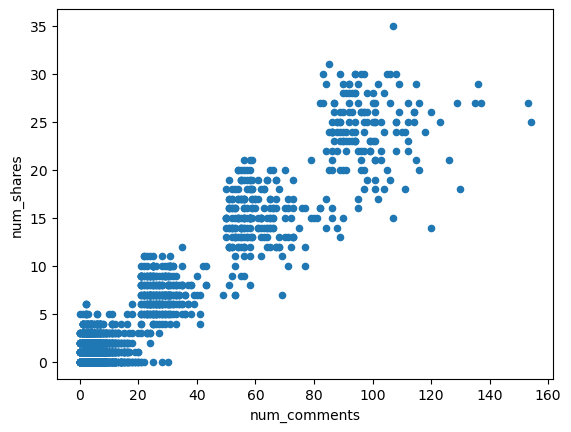

In [21]:
X = firm[["num_comments", "num_shares"]]
X.plot.scatter(x="num_comments", y="num_shares")

#### QUESTION #2: Provide a screenshot of the figure. How many clusters do you observe? 
\
I see four clusters in the scatter plot. They line up diagonally from low to high engagement, which shows that posts with more comments also tend to get more shares.

2.2. Before clustering, think about the two variables you're using. Clustering algorithms like k-means rely on distance between points. If one variable is measured on a much larger scale than the other, it can dominate that distance calculation. 

In [22]:
print(X.describe())
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled, columns=["num_comments", "num_shares"])
X_scaled["num_comments"].max()

       num_comments   num_shares
count   2466.000000  2466.000000
mean      18.780616     4.637064
std       27.141731     6.793033
min        0.000000     0.000000
25%        3.000000     0.000000
50%        6.000000     2.000000
75%       24.000000     6.000000
max      154.000000    35.000000


4.9829839261650095

#### QUESTION #3: Look at the scale (min/max range) of your two variables. Do you expect one variable to dominate a distance-based calculation if left unscaled? Explain your reasoning, then identify a preprocessing step that would address this problem and apply it to your two-column DataFrame. 
\
Yes, comments would dominate if the data were left unscaled. Comments range from 0 to 154, while shares only range from 0 to 35. K-means uses Euclidean distance, so differences in comments would count more just because the numbers are bigger. To fix this, I standardized both columns with StandardScaler, which gives each a mean of 0 and a standard deviation of 1, so both count equally.

#### QUESTION #4: What is the maximum value under the “num_comments” column after pre-processing?
\
After standardizing, the maximum value of num_comments is about 4.98.

2.3. Use the “KMeans” implementation from the “sklearn.cluster” package in scikit-learn to cluster the data into 4 groups. • For KMeans configuration, you need to set “n_clusters” to 4. Leave other hyperparameters as default. • After the clustering operation, you can obtain the cluster labels of observations by calling the “.labels_” attribute. 

In [23]:
km = KMeans(n_clusters=4)
km.fit(X_scaled)
km.labels_

array([1, 1, 1, ..., 3, 1, 2], shape=(2466,), dtype=int32)

2.4. Draw the scatter plot once again, but this time assign colors to the observations based on their cluster labels. You can use the “c” parameter in the scatter plot method to do the coloring based on labels. You can also use the “colormap” parameter to differentiate clusters using different / vibrant colors. For different colormap options, see: https://matplotlib.org/stable/tutorials/colors/colormaps.html. 

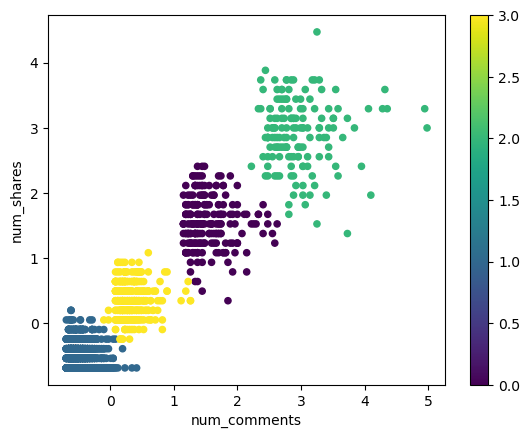

cluster
1    1769
3     326
0     219
2     152
Name: count, dtype: int64
         num_comments  num_shares
cluster                          
0           60.598174   15.168950
1            4.994912    1.181458
2           99.486842   24.407895
3           27.865031    7.095092


In [25]:
X_scaled.plot.scatter(x="num_comments", y="num_shares", c=km.labels_, colormap="viridis")
plt.show()

firm2 = firm.copy()
firm2["cluster"] = km.labels_
print(firm2["cluster"].value_counts())
print(firm2.groupby("cluster")[["num_comments", "num_shares"]].mean())

#### QUESTION #5: Provide a screenshot of the figure. 

#### QUESTION #6: In a few sentences, describe what the four clusters seem to represent in business terms. For example, is there a group of posts that generated unusually high shares relative to comments ("viral" content), or a cluster of low-engagement posts? Is there anything that you can recommend to the firm's social media team based on this pattern? 
\
The four clusters represent levels of engagement:

- The largest cluster, about 1,769 posts (roughly 72%), is low-engagement posts, with about 5 comments and 1 share on average.
- The next is moderate posts, with about 28 comments and 7 shares.
- Then high-engagement posts, with about 61 comments and 15 shares.
- The smallest cluster, about 152 posts, is the “viral” content, with about 100 comments and 24 shares.

Comments and shares rise together, so the clusters show levels of engagement rather than different kinds of engagement. I would recommend that the social media team study what the top-cluster posts have in common, such as topic, timing or style, and create more content like them, since most of their posts get very little interaction.

2.5. Now, go back to the KMeans model and set the number of algorithm runs to 1 using the “n_init” hyperparameter (this is 10 by default). Re-run the K-means fitting and scatter plot code multiple times. You should observe some differences across various outcome plots. 

<Axes: xlabel='num_comments', ylabel='num_shares'>

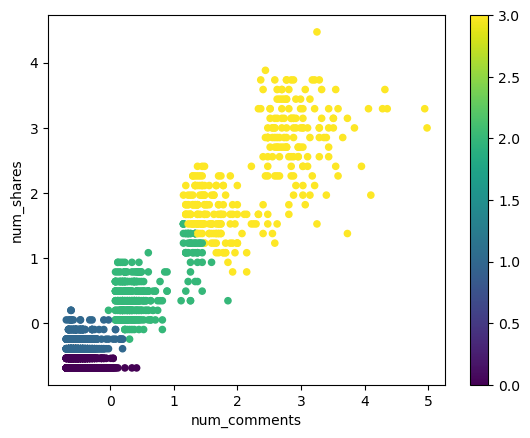

In [28]:
km = KMeans(n_clusters=4, n_init=1, init="random")
km.fit(X_scaled)
X_scaled.plot.scatter(x="num_comments", y="num_shares", c=km.labels_, colormap="viridis")

#### QUESTION #7: Provide screenshots of at least 2 different clustering outcomes (not just color change, but different groupings). What is this problem called, and why does it happen in k-means specifically? How can we address this issue? Your answer should reference what the "n_init" parameter actually does. 
\
This problem is called sensitivity to the initial centroids, and it can cause k-means to get stuck in a local minimum. K-means starts from randomly chosen centroids and only improves from there. If two centroids start in the same natural group, the algorithm can end with a worse clustering and a higher SSE. In my runs, the good result had an SSE of about 259, while the bad ones were about 544. The n_init parameter addresses this: it runs k-means several times with different starting centroids and keeps the run with the lowest SSE. The lab describes the default as 10 runs; newer versions of scikit-learn use “auto”, which is 1 run with k-means++.

2.6. Reset the “n_init” to default by deleting the argument or setting it to 10. 

In [30]:
km = KMeans(n_clusters=4, n_init=10)
km.fit(X_scaled)

,n_clusters,4
,init,'k-means++'
,n_init,10
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,None
,copy_x,True
,algorithm,'lloyd'


#### STEP 3: Experimenting with Different Number of Clusters 
3.1. In the previous step, we were given the number of clusters to be 4 (i.e., k =4). As discussed in the class, a requirement of the k-means algorithm is to have a pre-determined number of clusters. While there is no best approach to find the k optimally, you can use the “elbow method” to identify an ideal number. To do this, you will need to calculate the sum of squared errors (SSE) for different k values and plot the results using a line chart.  
- The point where the line “bends” the most is considered to be an ideal k value as incrementing the k after this point would have marginally less impact on reducing the SSE.

3.2. The SSE of the a k-means output can be retrieved by calling the “.inertia_” attribute. Write a for loop that iterates over k values between 2 and 7 and stores the SSE for each k in a list. Next, create a line chart using the values in the SSE list. 

[1012.879748570181, 585.8259034183268, 258.98658531230444, 218.27463350651735, 190.43957107314282, 169.51290872937565]


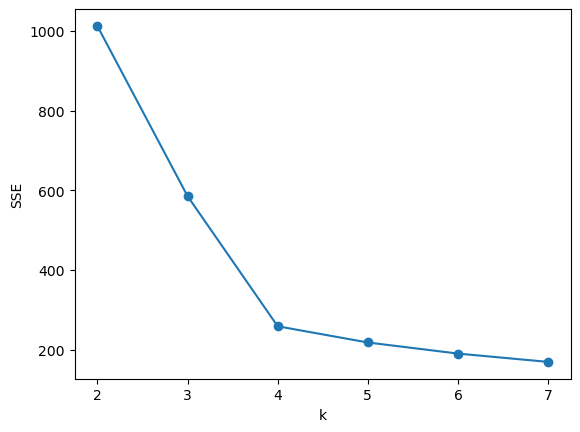

In [31]:
sse = []
for k in range(2, 8):
    km_k = KMeans(n_clusters=k, n_init=10)
    km_k.fit(X_scaled)
    sse.append(km_k.inertia_)

print(sse)
plt.plot(range(2, 8), sse, marker="o")
plt.xlabel("k")
plt.ylabel("SSE")
plt.show()

#### QUESTION #8: Provide the line chart. By looking at this chart, can you identify an ideal k value for this data set? 
\
Yes, the ideal k is 4. The SSE drops sharply from k = 2 (about 1013) to k = 4 (about 259), then only decreases slightly for k = 5, 6 and 7. The line bends the most at k = 4, so adding more clusters after that doesn’t improve the results much. This also matches the four groups seen in the scatter plot.

#### STEP 4: Debugging 
4.1. Above is a short code script to cluster the same two attributes. It runs without throwing an error, but it has two mistakes that affect the validity of the results. 

In [32]:
X = firm[["num_comments", "num_shares"]]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

km = KMeans(n_clusters=4)
km.fit(X_scaled)

inertia_values = []
for k in range(2, 8):
    km_k = KMeans(n_clusters=k)
    km_k.fit(X_scaled)
    inertia_values.append(km_k.inertia_)
inertia_values

[1012.879748570181,
 587.6448052916296,
 258.98658531230444,
 218.2746335065172,
 197.72843652105735,
 176.2153604132612]

#### QUESTION #9: Identify both mistakes in the code above, explain why each one is a problem. Finally, rewrite the corrected version. 

- Mistake 1: km.fit(X) uses the unscaled data instead of X_scaled. The scaling step is wasted, and comments dominate the distance calculation because of their larger range. It should be km.fit(X_scaled).
- Mistake 2: inertia_values = [] is inside the for loop, so the list resets to empty every time through. At the end it only holds the SSE for k = 7, so there’s no elbow chart to draw. The empty list should be created before the loop.